In [ ]:

# ============================================
# SIMPLE RNN - TIME SERIES PREDICTION
# ============================================

# Step 1: Import libraries
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Input



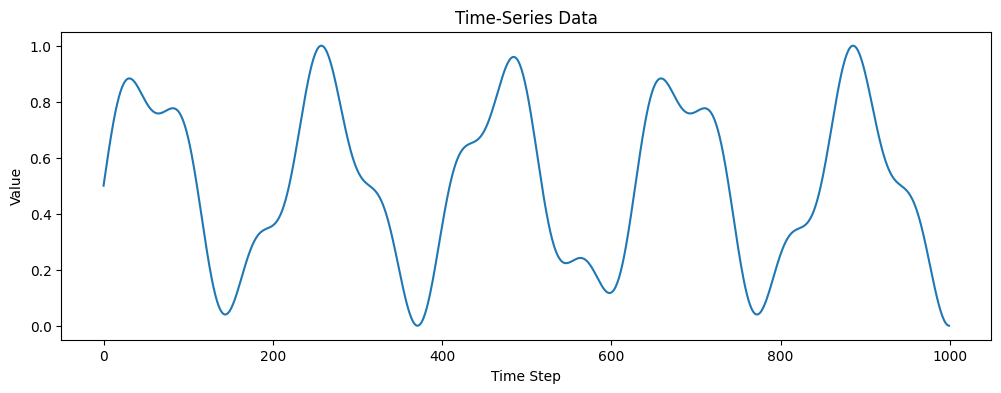

X shape: (980, 20, 1)
y shape: (980,)


In [ ]:
# Step 2: Set random seeds
np.random.seed(42)
tf.random.set_seed(42)

# Step 3: Create sample time-series data
time = np.arange(1000)

data = (
    np.sin(time * 0.03)
    + 0.3 * np.sin(time * 0.08)
)

# Normalize data between 0 and 1
data = (data - data.min()) / (data.max() - data.min())

# Visualize the data
plt.figure(figsize=(12, 4))
plt.plot(data)
plt.title("Time-Series Data")
plt.xlabel("Time Step")
plt.ylabel("Value")
plt.show()

# Step 4: Prepare sequences
sequence_length = 20

X = []
y = []

for i in range(len(data) - sequence_length):
    X.append(data[i:i + sequence_length])
    y.append(data[i + sequence_length])

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.float32)

# RNN input shape: (samples, time steps, features)
X = X.reshape(X.shape[0], X.shape[1], 1)

print("X shape:", X.shape)
print("y shape:", y.shape)




In [ ]:
# Step 5: Split data chronologically
split_index = int(len(X) * 0.8)

X_train = X[:split_index]
y_train = y[:split_index]

X_test = X[split_index:]
y_test = y[split_index:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# Step 6: Build the Simple RNN model
model = Sequential([
    Input(shape=(sequence_length, 1)),
    SimpleRNN(32, activation="tanh"),
    Dense(1)
])

# Step 7: Display model architecture
model.summary()

# Step 8: Compile the model
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)



Training samples: 784
Testing samples: 196


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,121 (4.38 KB)

 Trainable params: 1,121 (4.38 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Step 9: Train the model
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    verbose=1
)



Epoch 1/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 4s 53ms/step - loss: 0.0181 - mae: 0.1007 - val_loss: 0.0073 - val_mae: 0.0676
Epoch 2/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0021 - mae: 0.0351 - val_loss: 9.6629e-04 - val_mae: 0.0212
Epoch 3/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 5.1330e-04 - mae: 0.0163 - val_loss: 4.6054e-04 - val_mae: 0.0190
Epoch 4/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 5.4730e-04 - mae: 0.0189 - val_loss: 6.6211e-04 - val_mae: 0.0223
Epoch 5/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 6.8182e-04 - mae: 0.0194 - val_loss: 3.8323e-04 - val_mae: 0.0166
Epoch 6/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 8.6113e-04 - mae: 0.0229 - val_loss: 3.9178e-04 - val_mae: 0.0153
Epoch 7/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 6.6180e-04 - mae: 0.0182 - val_loss: 8.0760e-04 - val_mae: 0.0225
Epoch 8/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 5.0280e-04 - mae: 0.0161 - val_loss: 2.5542e-04 - val_mae: 0.0130
Epoch 9/20
23/23

In [ ]:
# Step 10: Evaluate the model
test_loss, test_mae = model.evaluate(
    X_test, y_test, verbose=0
)

print("Test MSE:", round(test_loss, 5))
print("Test MAE:", round(test_mae, 5))

# Step 11: Predict test values
predictions = model.predict(X_test, verbose=0).flatten()

print("\nActual values:")
print(np.round(y_test[:10], 3))

print("\nPredicted values:")
print(np.round(predictions[:10], 3))



Test MSE: 0.00014
Test MAE: 0.00993

Actual values:
[0.287 0.293 0.3   0.305 0.311 0.316 0.32  0.324 0.328 0.331]

Predicted values:
[0.288 0.295 0.301 0.307 0.312 0.317 0.321 0.325 0.328 0.331]


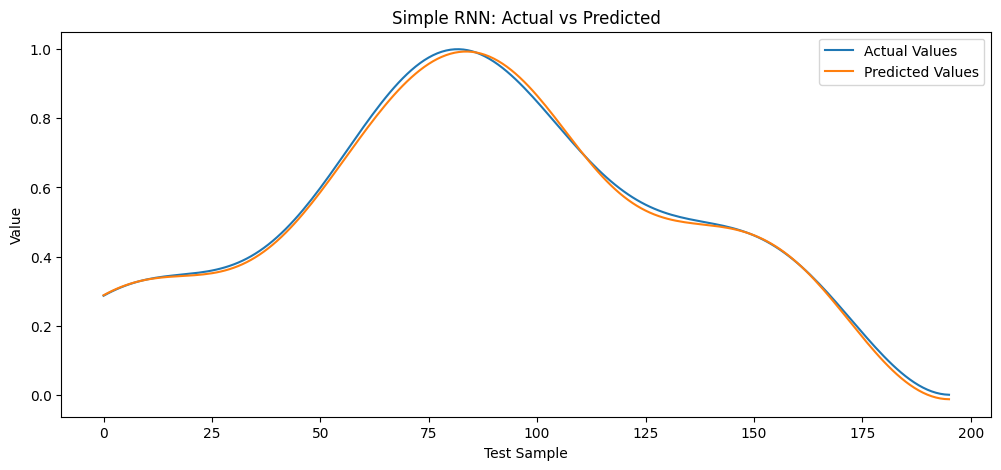

In [ ]:
# Step 12: Compare actual vs predicted values
plt.figure(figsize=(12, 5))
plt.plot(y_test, label="Actual Values")
plt.plot(predictions, label="Predicted Values")
plt.title("Simple RNN: Actual vs Predicted")
plt.xlabel("Test Sample")
plt.ylabel("Value")
plt.legend()
plt.show()



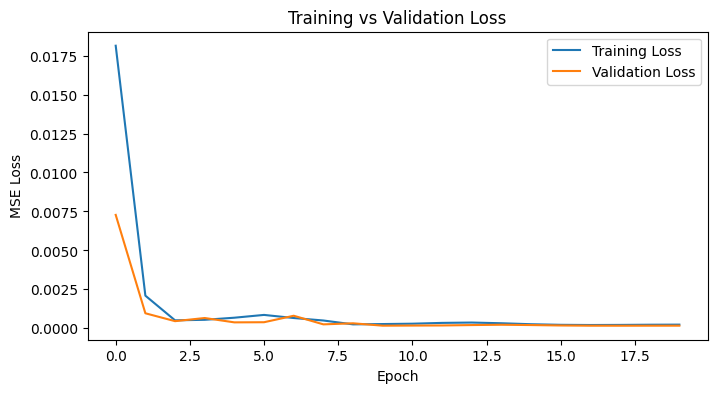

In [ ]:
# Step 13: Plot training and validation loss
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.show()



In [ ]:
# Step 14: Predict the next value
latest_sequence = data[-sequence_length:]
latest_sequence = latest_sequence.reshape(1, sequence_length, 1)

next_value = model.predict(latest_sequence, verbose=0)[0, 0]

print("\nPredicted next value:", round(float(next_value), 4))


Predicted next value: -0.0124
